# IntelliSched: EDA and Classical EWMA Baseline

This notebook completes **Task 2** of the IntelliSched project. It explores the CPU burst dataset and evaluates the traditional EWMA prediction as a baseline. The code is intentionally simple and uses one cell for each step.

## 1. Import libraries

This cell imports the libraries needed for data handling, visualizations, numerical calculations, and evaluation metrics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## 2. Load the dataset

The CSV file is loaded into a pandas DataFrame. The shape confirms the number of rows and columns.

In [2]:
df = pd.read_csv("sjf_ml_training_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (12000, 12)


,prev_burst_1,prev_burst_2,prev_burst_3,avg_burst,std_burst,ewma_burst_estimate,cpu_utilization,memory_usage_mb,thread_count,avg_io_wait_ms,avg_io_count,next_burst_ms
0,14.829,12.968,15.927,14.574,1.221,14.638,54.668,316.002,4,10.931,4.333,14.911
1,14.911,14.829,12.968,14.236,0.897,14.774,52.067,316.002,4,11.730,4.500,15.791
2,15.791,14.911,14.829,15.177,0.436,15.283,62.679,316.002,4,8.367,4.000,14.108
3,14.108,15.791,14.911,14.937,0.687,14.695,59.845,316.002,4,10.220,2.667,17.694
4,17.694,14.108,15.791,15.864,1.465,16.195,62.187,316.002,4,9.587,4.429,19.925


## 3. Understand the dataset

These checks show the available column names, data types, non-null values, and basic statistics.

In [3]:
print("Column names:")
print(df.columns.tolist())

Column names:
['prev_burst_1', 'prev_burst_2', 'prev_burst_3', 'avg_burst', 'std_burst', 'ewma_burst_estimate', 'cpu_utilization', 'memory_usage_mb', 'thread_count', 'avg_io_wait_ms', 'avg_io_count', 'next_burst_ms']


In [4]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   prev_burst_1         12000 non-null  float64
 1   prev_burst_2         12000 non-null  float64
 2   prev_burst_3         12000 non-null  float64
 3   avg_burst            12000 non-null  float64
 4   std_burst            12000 non-null  float64
 5   ewma_burst_estimate  12000 non-null  float64
 6   cpu_utilization      12000 non-null  float64
 7   memory_usage_mb      12000 non-null  float64
 8   thread_count         12000 non-null  int64  
 9   avg_io_wait_ms       12000 non-null  float64
 10  avg_io_count         12000 non-null  float64
 11  next_burst_ms        12000 non-null  float64
dtypes: float64(11), int64(1)
memory usage: 1.1 MB


In [5]:
print("Statistical summary:")
df.describe()

Statistical summary:


,prev_burst_1,prev_burst_2,prev_burst_3,avg_burst,std_burst,ewma_burst_estimate,cpu_utilization,memory_usage_mb,thread_count,avg_io_wait_ms,avg_io_count,next_burst_ms
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.00000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,17.654727,17.679154,17.684859,17.672913,1.508530,17.67054,53.292585,407.163814,3.679000,12.741165,4.835914,17.650882
std,12.964941,12.986480,12.989875,12.828762,1.280157,12.79561,30.471172,203.861758,1.948403,8.428071,2.470858,12.964243
min,0.728000,0.728000,0.728000,1.678000,0.008000,1.79800,5.000000,64.000000,1.000000,1.428000,0.000000,0.595000
25%,6.195500,6.225000,6.218000,6.395750,0.540000,6.44450,23.183250,238.299000,2.000000,3.353750,2.462000,6.195500
50%,14.353000,14.335500,14.289000,14.793500,1.104000,14.96700,58.429000,361.125000,3.000000,10.970500,4.500000,14.363000
75%,29.143750,29.158750,29.131500,29.757250,2.135000,29.88725,88.617000,573.425750,5.000000,20.963250,6.929000,29.041250
max,58.006000,57.639000,57.639000,54.540000,9.086000,53.95900,99.000000,1016.819000,8.000000,32.022000,12.667000,58.006000


## 4. Data quality checks

This cell checks for missing values in each column and for duplicate rows.

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:
prev_burst_1           0
prev_burst_2           0
prev_burst_3           0
avg_burst              0
std_burst              0
ewma_burst_estimate    0
cpu_utilization        0
memory_usage_mb        0
thread_count           0
avg_io_wait_ms         0
avg_io_count           0
next_burst_ms          0
dtype: int64

Total missing values: 0
Duplicate rows: 0


## 5. Exploratory data analysis visualizations

The following plots show the target distribution, the relationship between previous bursts and the next burst, the relationship between the classical EWMA estimate and the next burst, and correlations among numerical columns.

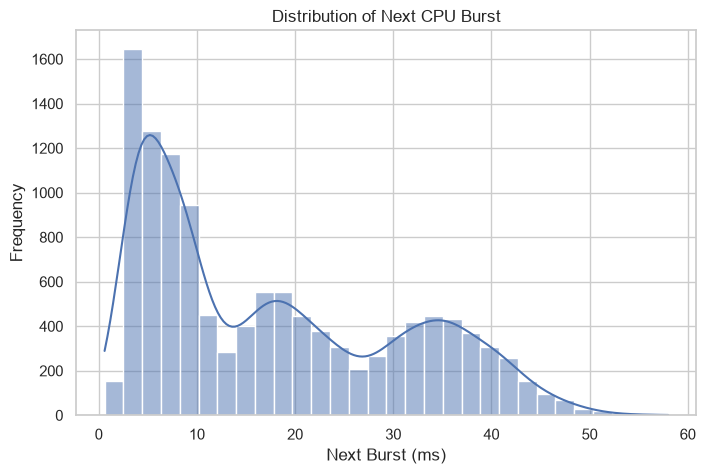

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df["next_burst_ms"], bins=30, kde=True)
plt.title("Distribution of Next CPU Burst")
plt.xlabel("Next Burst (ms)")
plt.ylabel("Frequency")
plt.show()

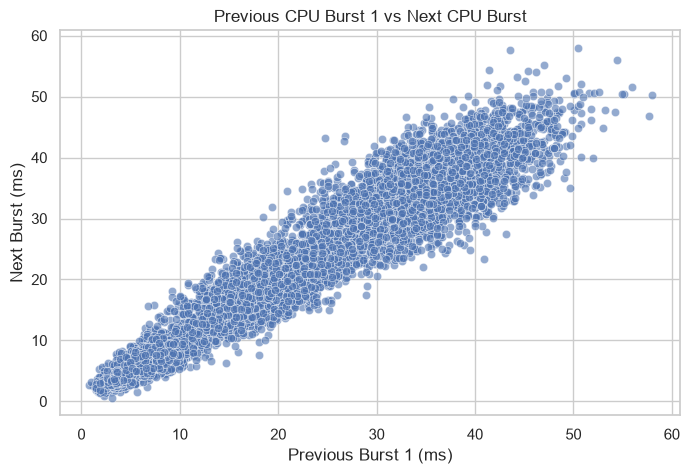

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="prev_burst_1", y="next_burst_ms", alpha=0.6)
plt.title("Previous CPU Burst 1 vs Next CPU Burst")
plt.xlabel("Previous Burst 1 (ms)")
plt.ylabel("Next Burst (ms)")
plt.show()

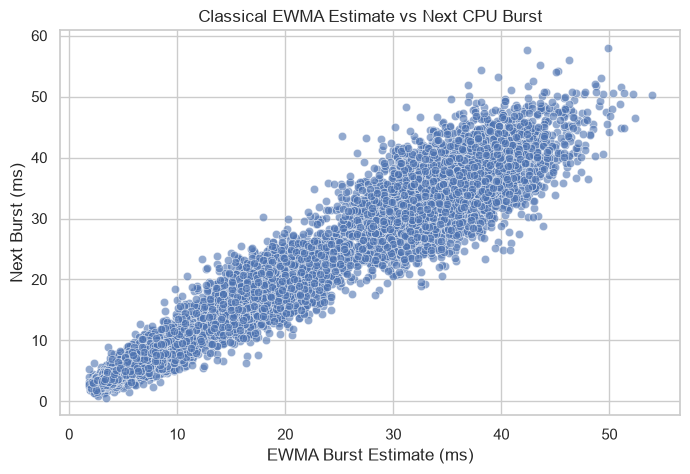

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="ewma_burst_estimate", y="next_burst_ms", alpha=0.6)
plt.title("Classical EWMA Estimate vs Next CPU Burst")
plt.xlabel("EWMA Burst Estimate (ms)")
plt.ylabel("Next Burst (ms)")
plt.show()

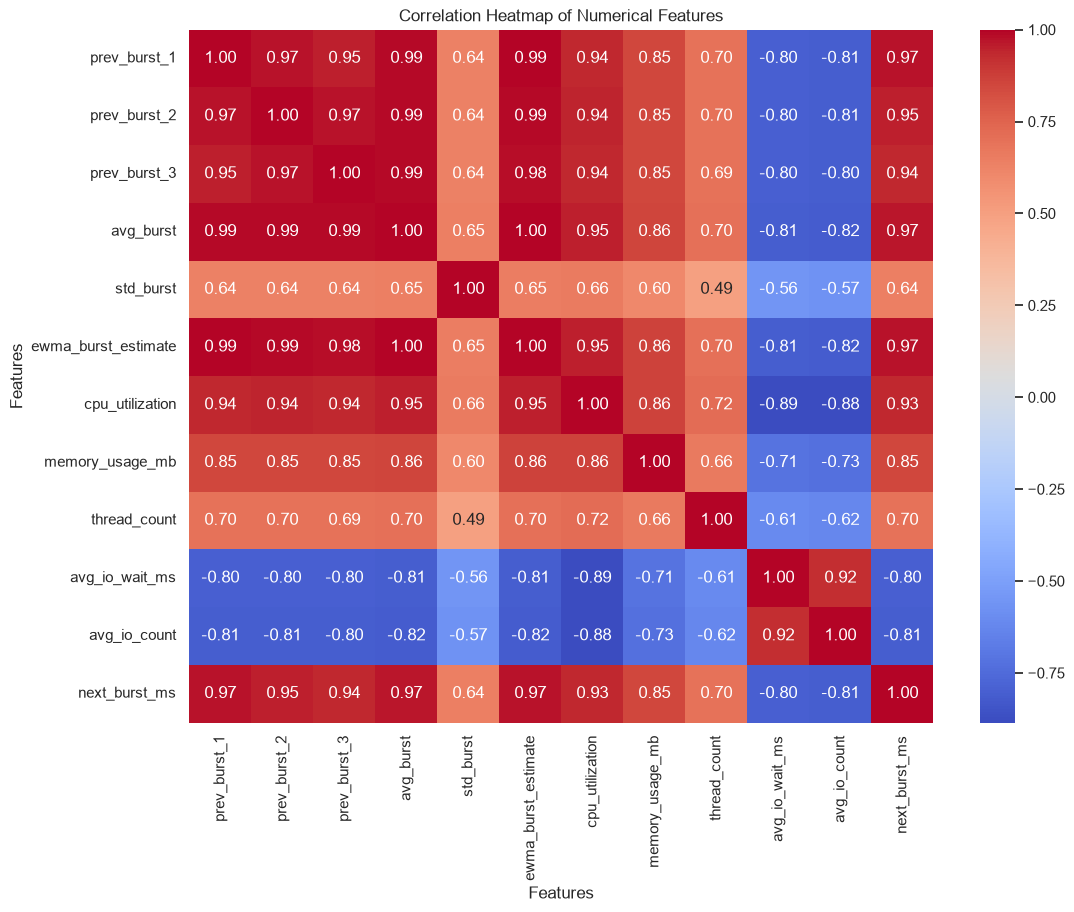

In [10]:
plt.figure(figsize=(12, 9))
correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

## 6. Classical EWMA baseline

The traditional EWMA formula is:

$$T(n+1) = \alpha \times t(n) + (1 - \alpha) \times T(n)$$

The dataset already contains the calculated classical estimate in `ewma_burst_estimate`. We compare that estimate with the actual `next_burst_ms` values using MAE, RMSE, and R² Score.

In [11]:
actual = df["next_burst_ms"]
ewma_prediction = df["ewma_burst_estimate"]

mae = mean_absolute_error(actual, ewma_prediction)
rmse = np.sqrt(mean_squared_error(actual, ewma_prediction))
r2 = r2_score(actual, ewma_prediction)

print("Classical EWMA Baseline Metrics")
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

Classical EWMA Baseline Metrics
MAE: 2.1523320833333335
RMSE: 3.104307590201611
R² Score: 0.9426581984895275


## 7. Final result

This table provides a compact summary of the baseline performance.

In [12]:
results = pd.DataFrame({
        "Model": ["EWMA Baseline"],
        "MAE": [mae],
        "RMSE": [rmse],
        "R²": [r2]
    })

results

,Model,MAE,RMSE,R²
0,EWMA Baseline,2.152332,3.104308,0.942658


## 8. Conclusion

The EDA shows the distribution of the next CPU burst and how it relates to recent CPU burst history and the EWMA estimate. Previous CPU bursts are useful because a process's recent execution history can provide information about its next burst duration. EWMA gives more importance to recent burst observations while still keeping some information from older observations. It is used as the baseline because it is simple, traditional, and provides a clear reference point for prediction quality. In the next task, Random Forest and XGBoost predictions will be compared against this EWMA baseline.